In [8]:
import json
import os
import random
import numpy as np
from datetime import datetime
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerTuple

# ==========================================
# 1. 공통 유틸리티 수학 함수
# ==========================================
def get_richardson_weights(lam_points):
    weights = []
    target = 0.0 
    for i, l_i in enumerate(lam_points):
        w = 1.0
        for j, l_j in enumerate(lam_points):
            if i != j:
                w *= (target - l_j) / (l_i - l_j)
        weights.append(w)
    return weights

def get_chebyshev_lobatto_nodes(lam_min=1.0, lam_max=4.0, N=8):
    if N == 1:
        return [lam_min]
    nodes = []
    for k in range(1, N + 1):
        lam_k = (lam_max + lam_min) / 2 - (lam_max - lam_min) / 2 * np.cos((k - 1) / (N - 1) * np.pi)
        nodes.append(round(lam_k, 3))
    return nodes

def get_pec_gamma(p10, p01, p11):
    p00 = 1.0 - (p10 + p01 + p11)
    p_vec = np.array([p00, p01, p10, p11])
    H = np.array([
        [1,  1,  1,  1],
        [1, -1,  1, -1],
        [1,  1, -1, -1],
        [1, -1, -1,  1]
    ])
    lambdas = H @ p_vec
    L_inv = np.divide(1.0, lambdas, out=np.zeros_like(lambdas), where=lambdas!=0)
    return 0.25 * (H @ L_inv)

def get_pec_params(p10, p01, p11):
    gamma = get_pec_gamma(p10, p01, p11)
    gamma_norm = np.sum(np.abs(gamma))
    q_dist = np.abs(gamma) / gamma_norm
    signs = np.sign(gamma)
    return gamma_norm, q_dist, signs

# ==========================================
# 2. Observable 평가 로직 (Phase-Vector 기반)
# ==========================================
def calc_phase_vector(prob_dict, l):
    O_c, O_s = 0.0, 0.0
    for bitstring, prob in prob_dict.items():
        y_x = int(bitstring, 2)
        phi_hat = y_x / (2**l)
        angle = 2 * np.pi * phi_hat
        O_c += prob * np.cos(angle)
        O_s += prob * np.sin(angle)
    return O_c, O_s

def calc_phase_mse(obs_val, obs_ideal):
    Oc, Os = obs_val
    Oc0, Os0 = obs_ideal
    # 유클리디안 거리 (제곱 없음)
    return np.sqrt((Oc - Oc0)**2 + (Os - Os0)**2)

# ==========================================
# 3. 해석적 (Analytical) 엔진 
# ==========================================
I = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
H_mat = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
P0 = np.array([[1, 0], [0, 0]], dtype=complex) 
P1 = np.array([[0, 0], [0, 1]], dtype=complex) 

I0 = np.kron(I, I)
X0 = np.kron(X, I)
H0 = np.kron(H_mat, I)

def Phase(theta): return np.array([[1, 0], [0, np.exp(1j * theta)]], dtype=complex)
def Rz_mat(theta): return np.array([[np.exp(-1j * theta / 2), 0], [0, np.exp(1j * theta / 2)]], dtype=complex)
def Rz0_gate(theta): return np.kron(Rz_mat(theta), I)
def CU_gate(U): return np.kron(P0, I) + np.kron(P1, U)

def get_E_ab_k(a, b, k):
    bra_idx = k ^ a         
    ket_idx = k ^ b         
    E = np.zeros((2, 2), dtype=complex)
    E[bra_idx, ket_idx] = 1.0
    return E

def base_measurement_channel(rho, p10, p01, p11):
    weights = {(0,0): 1.0 - (p10+p01+p11), (1,0): p10, (0,1): p01, (1,1): p11}
    rho_k0, rho_k1 = np.zeros_like(rho), np.zeros_like(rho)
    for a in [0, 1]:
        for b in [0, 1]:
            E_ab0 = np.kron(get_E_ab_k(a, b, k=0), I)
            rho_k0 += weights[(a,b)] * (E_ab0 @ rho @ E_ab0.conj().T)
            E_ab1 = np.kron(get_E_ab_k(a, b, k=1), I)
            rho_k1 += weights[(a,b)] * (E_ab1 @ rho @ E_ab1.conj().T)
    return rho_k0, rho_k1

def E00_channel(rho, p10, p01, p11): return base_measurement_channel(rho, p10, p01, p11)
def E01_channel(rho, p10, p01, p11): return base_measurement_channel(X0 @ rho @ X0.conj().T, p10, p01, p11)
def E10_channel(rho, p10, p01, p11):
    r0, r1 = base_measurement_channel(rho, p10, p01, p11)
    return X0 @ r0 @ X0.conj().T, X0 @ r1 @ X0.conj().T
def E11_channel(rho, p10, p01, p11):
    r0, r1 = base_measurement_channel(X0 @ rho @ X0.conj().T, p10, p01, p11)
    return X0 @ r0 @ X0.conj().T, X0 @ r1 @ X0.conj().T

def boosted_measurement_channel(rho, p10, p01, p11, lam):
    gamma = get_pec_gamma(p10, p01, p11)
    alpha_00 = (1 - lam) * gamma[0] + lam
    alpha_01 = (1 - lam) * gamma[1]
    alpha_10 = (1 - lam) * gamma[2]
    alpha_11 = (1 - lam) * gamma[3]
    
    if any(a < 0 for a in [alpha_00, alpha_01, alpha_10, alpha_11]):
        r = lam - 1.0
        alpha_01, alpha_10, alpha_11 = r * p01, r * p10, r * p11
        alpha_00 = 1.0 - (alpha_01 + alpha_10 + alpha_11)
        
    r0_00, r1_00 = E00_channel(rho, p10, p01, p11)
    r0_01, r1_01 = E01_channel(rho, p10, p01, p11)
    r0_10, r1_10 = E10_channel(rho, p10, p01, p11)
    r0_11, r1_11 = E11_channel(rho, p10, p01, p11)
    
    return (alpha_00*r0_00 + alpha_01*r0_01 + alpha_10*r0_10 + alpha_11*r0_11), \
           (alpha_00*r1_00 + alpha_01*r1_01 + alpha_10*r1_10 + alpha_11*r1_11)

def pec_measurement_channel(rho, p10, p01, p11):
    gamma_raw = get_pec_gamma(p10, p01, p11)
    r0_00, r1_00 = E00_channel(rho, p10, p01, p11)
    r0_01, r1_01 = E01_channel(rho, p10, p01, p11)
    r0_10, r1_10 = E10_channel(rho, p10, p01, p11)
    r0_11, r1_11 = E11_channel(rho, p10, p01, p11)
    
    rho_out_0 = gamma_raw[0]*r0_00 + gamma_raw[1]*r0_01 + gamma_raw[2]*r0_10 + gamma_raw[3]*r0_11
    rho_out_1 = gamma_raw[0]*r1_00 + gamma_raw[1]*r1_01 + gamma_raw[2]*r1_10 + gamma_raw[3]*r1_11
    return rho_out_0, rho_out_1

def qpe_analytical(target_gate, u_state, p10, p01, p11, mitigation_type="raw", lam=1.0, l=7):
    target_rho = P1 if u_state == '1' else H_mat @ P0 @ H_mat.conj().T if u_state == '+' else P0
    branches = [(np.kron(P0, target_rho), 1.0, ())] 
    if target_gate == 'S': base_angle = np.pi / 2
    elif target_gate == 'T': base_angle = np.pi / 4
    elif target_gate == 'U_pi/3': base_angle = np.pi / 3
    else: raise ValueError(f"Unsupported gate: {target_gate}")
    powers = [2**(l - 1 - k) for k in range(l)]
    
    for round_k, power in enumerate(powers):
        new_branches = []
        for rho, p_branch, c_tuple in branches:
            rho = H0 @ rho @ H0.conj().T
            angle = (base_angle * power) % (2 * np.pi)
            if not np.isclose(angle, 0.0) and not np.isclose(angle, 2 * np.pi):
                CU = CU_gate(Phase(angle))
                rho = CU @ rho @ CU.conj().T
            
            for prev_k in range(round_k):
                if c_tuple[prev_k] == 1:
                    angle_iqft = -2 * np.pi / (2 ** (round_k - prev_k + 1))
                    rho = Rz0_gate(angle_iqft) @ rho @ Rz0_gate(angle_iqft).conj().T
                    
            rho = H0 @ rho @ H0.conj().T
            
            if mitigation_type == "ideal": rho_out_0, rho_out_1 = base_measurement_channel(rho, 0.0, 0.0, 0.0)
            elif mitigation_type == "pec": rho_out_0, rho_out_1 = pec_measurement_channel(rho, p10, p01, p11)
            else: rho_out_0, rho_out_1 = boosted_measurement_channel(rho, p10, p01, p11, lam)
            
            p_obs_0, p_obs_1 = np.trace(rho_out_0).real, np.trace(rho_out_1).real
            if p_obs_0 > 1e-12: new_branches.append((rho_out_0 / p_obs_0, p_branch * p_obs_0, c_tuple + (0,)))
            if p_obs_1 > 1e-12: new_branches.append((X0 @ (rho_out_1 / p_obs_1) @ X0.conj().T, p_branch * p_obs_1, c_tuple + (1,)))
        branches = new_branches
        
    results = {f"{b:0{l}b}": 0.0 for b in range(2**l)}
    for _, p_branch, c_tuple in branches:
        bitstring = "".join(str(c_tuple[idx]) for idx in reversed(range(l)))
        results[bitstring] += p_branch
    return results

# ==========================================
# 4. 수치적 (Numerical) 엔진
# ==========================================
def build_qpe_shots_numerical(target_gate, u_state, p10, p01, p11, lam, num_shots, l=7):
    gamma = get_pec_gamma(p10, p01, p11)
    alpha_00 = (1 - lam) * gamma[0] + lam
    alpha_01 = (1 - lam) * gamma[1]
    alpha_10 = (1 - lam) * gamma[2]
    alpha_11 = (1 - lam) * gamma[3]
    
    if any(a < 0 for a in [alpha_00, alpha_01, alpha_10, alpha_11]):
        r = lam - 1.0
        a_01, a_10, a_11 = r * p01, r * p10, r * p11
    else:
        a_01, a_10, a_11 = alpha_01, alpha_10, alpha_11

    if target_gate == 'S': base_angle = np.pi / 2
    elif target_gate == 'T': base_angle = np.pi / 4
    elif target_gate == 'U_pi/3': base_angle = np.pi / 3
    else: raise ValueError(f"Unsupported gate: {target_gate}")
    circuits = []
    powers = [2**(l - 1 - k) for k in range(l)]
    
    for _ in range(num_shots):
        qr = QuantumRegister(2, 'q')
        cr = ClassicalRegister(l, 'c')
        qc = QuantumCircuit(qr, cr)
        
        if u_state == '1': qc.x(1)
        elif u_state == '+': qc.h(1)
            
        for k, power in enumerate(powers):
            qc.h(0)
            angle = (base_angle * power) % (2 * np.pi)
            if not np.isclose(angle, 0.0) and not np.isclose(angle, 2 * np.pi): qc.cp(angle, 0, 1)
            for prev_k in range(k):
                with qc.if_test((cr[prev_k], 1)): qc.p(-2 * np.pi / (2 ** (k - prev_k + 1)), 0)
            qc.h(0)
            
            virt_pre, virt_post = False, False
            rand_virt = random.random()
            if rand_virt < a_01: virt_pre = True
            elif rand_virt < a_01 + a_10: virt_post = True
            elif rand_virt < a_01 + a_10 + a_11: virt_pre, virt_post = True, True
                
            base_pre, base_post = False, False
            rand_base = random.random()
            if rand_base < p01: base_pre = True
            elif rand_base < p01 + p10: base_post = True
            elif rand_base < p01 + p10 + p11: base_pre, base_post = True, True

            if virt_pre: qc.x(0)
            if base_pre: qc.x(0)
            qc.measure(0, cr[k])
            if base_post: qc.x(0)
            if virt_post: qc.x(0)
            
            with qc.if_test((cr[k], 1)): qc.x(0)
        circuits.append(qc)
    return circuits

def build_qpe_shots_pec_numerical(target_gate, u_state, p10, p01, p11, num_shots, l=7):
    gamma_norm, q_dist, signs = get_pec_params(p10, p01, p11)
    if target_gate == 'S': base_angle = np.pi / 2
    elif target_gate == 'T': base_angle = np.pi / 4
    elif target_gate == 'U_pi/3': base_angle = np.pi / 3
    else: raise ValueError(f"Unsupported gate: {target_gate}")
    circuits, shot_signs = [], []
    powers = [2**(l - 1 - k) for k in range(l)]
    
    for _ in range(num_shots):
        qr = QuantumRegister(2, 'q')
        cr = ClassicalRegister(l, 'c')
        qc = QuantumCircuit(qr, cr)
        
        if u_state == '1': qc.x(1)
        elif u_state == '+': qc.h(1)
        current_shot_sign = 1.0
            
        for k, power in enumerate(powers):
            qc.h(0)
            angle = (base_angle * power) % (2 * np.pi)
            if not np.isclose(angle, 0.0) and not np.isclose(angle, 2 * np.pi): qc.cp(angle, 0, 1)
            for prev_k in range(k):
                with qc.if_test((cr[prev_k], 1)): qc.p(-2 * np.pi / (2 ** (k - prev_k + 1)), 0)
            qc.h(0)
            
            rand_pec = random.random()
            pec_pre, pec_post = False, False
            if rand_pec < q_dist[0]: current_shot_sign *= signs[0]
            elif rand_pec < q_dist[0] + q_dist[1]: pec_pre = True; current_shot_sign *= signs[1]
            elif rand_pec < q_dist[0] + q_dist[1] + q_dist[2]: pec_post = True; current_shot_sign *= signs[2]
            else: pec_pre, pec_post = True, True; current_shot_sign *= signs[3]
                
            base_pre, base_post = False, False
            rand_base = random.random()
            if rand_base < p01: base_pre = True
            elif rand_base < p01 + p10: base_post = True
            elif rand_base < p01 + p10 + p11: base_pre, base_post = True, True
                
            if pec_pre: qc.x(0)
            if base_pre: qc.x(0)
            qc.measure(0, cr[k])
            if base_post: qc.x(0)
            if pec_post: qc.x(0) 
            with qc.if_test((cr[k], 1)): qc.x(0)
                
        circuits.append(qc)
        shot_signs.append(current_shot_sign)
    return circuits, shot_signs, gamma_norm

def execute_numerical(circuits, shots, l=7, seed=42):
    job = AerSimulator(seed_simulator=seed).run(circuits, shots=1)
    results = job.result()
    # 인덱스 변수 겹침 방지를 위해 b 사용
    counts = {f"{b:0{l}b}": 0 for b in range(2**l)}
    for i in range(shots):
        counts[list(results.get_counts(i).keys())[0]] += 1
    return {b: v/shots for b, v in counts.items()}

def execute_pec_numerical(circuits, shot_signs, gamma_norm, shots, l=7, seed=42):
    job = AerSimulator(seed_simulator=seed).run(circuits, shots=1)
    results = job.result()
    # 인덱스 변수 겹침 방지를 위해 b 사용
    pec_probs = {f"{b:0{l}b}": 0.0 for b in range(2**l)}
    total_weight = gamma_norm ** l 
    for i in range(shots):
        pec_probs[list(results.get_counts(i).keys())[0]] += shot_signs[i] * total_weight / shots
    
    return pec_probs

def apply_m3_mitigation(raw_dict, p01, p11, l=7):
    p_meas = p01 + p11 
    A_1q = np.array([[1 - p_meas, p_meas], [p_meas, 1 - p_meas]])
    A_nq_inv = np.linalg.inv(A_1q)
    for _ in range(l - 1): A_nq_inv = np.kron(A_nq_inv, np.linalg.inv(A_1q))
        
    bitstrings = [f"{b:0{l}b}" for b in range(2**l)]
    m3_vec = A_nq_inv @ np.array([raw_dict.get(b, 0) for b in bitstrings])
    return {b: p for b, p in zip(bitstrings, m3_vec)}

def check_approx_regime(p10, p01, p11, lam_points):
    gamma = get_pec_gamma(p10, p01, p11)
    for lam in lam_points:
        alphas = [(1 - lam) * gamma[0] + lam, (1 - lam) * gamma[1], (1 - lam) * gamma[2], (1 - lam) * gamma[3]]
        if any(a < 0 for a in alphas): return True
    return False

# ==========================================
# 5. 통합 파이프라인 및 프리미엄 시각화 
# ==========================================
def run_integrated_qem_sweep(target_gate='U_pi/3', u_state='+', error_profile=(1,1,1), N_nodes=3, lam_max=4.0, l=7, shots=5000, seed=None, save_dir='./results'):
    
    # 1. 시드가 주어지지 않으면 1부터 999999 사이의 랜덤 정수 생성
    if seed is None:
        seed = random.randint(1, 999999)
        
    # 난수 고정 (생성된 무작위 시드로 고정하여 재현성 완벽 확보)
    random.seed(seed)
    np.random.seed(seed)
    
    lam_points = get_chebyshev_lobatto_nodes(1.0, lam_max, N_nodes)
    
    print("="*60)
    print(f"  QEM PIPELINE SWEEP INITIALIZED")
    print("="*60)
    print(f"  [Configuration]")
    print(f"   - Random Seed   : {seed}")
    print(f"   - Target Gate   : {target_gate}")
    print(f"   - Initial State : |{u_state}>")
    print(f"   - Error Profile : {error_profile}")
    print(f"   - QPE Depth (l) : {l}")
    print(f"   - ZNE Nodes (N) : {N_nodes} (Max λ={lam_max})")
    print("-"*60)
    
    p_vals = np.round(np.arange(0.00, 0.25 + 0.0001, 0.01), 3)
    rich_weights = get_richardson_weights(lam_points)
    bitstrings = [f"{b:0{l}b}" for b in range(2**l)]
    
    p_ratio = np.array(error_profile, dtype=float)
    p_ratio /= np.sum(p_ratio)
    
    mse_records = {
        'ana_raw': [], 'ana_m3': [], 'ana_zne': [], 'ana_pec': [],
        'num_raw': [], 'num_m3': [], 'num_zne': [], 'num_pec': []
    }
    approx_flags = []
    
    # ---------------------------------------------------------
    # [NEW] p=0.0 일 때의 이상적인(Noiseless) 기준 기대값 추출
    # ---------------------------------------------------------
    ana_exact_0 = qpe_analytical(target_gate, u_state, 0.0, 0.0, 0.0, "raw", 1.0, l)
    ideal_obs = calc_phase_vector(ana_exact_0, l)
    print(f"  * Ideal Reference Vector (Oc, Os): ({ideal_obs[0]:.4f}, {ideal_obs[1]:.4f})")
    
    for p in p_vals:
        p01, p10, p11 = p * p_ratio[0], p * p_ratio[1], p * p_ratio[2]
        approx_flags.append(check_approx_regime(p10, p01, p11, lam_points))
        
        # 에러율 0.0 처리
        if p == 0.0:
            for k in ['ana_raw', 'ana_m3', 'ana_zne', 'ana_pec', 'num_raw', 'num_m3', 'num_zne', 'num_pec']:
                mse_records[k].append(0.0)
            continue
            
        # Analytical
        ana_exact = {lam: qpe_analytical(target_gate, u_state, p10, p01, p11, "raw", lam, l) for lam in lam_points}
        ana_pec = qpe_analytical(target_gate, u_state, p10, p01, p11, "pec", l=l)
        ana_m3 = apply_m3_mitigation(ana_exact[1.0], p01, p11, l)
        
        ana_zne_probs = np.zeros(2**l)
        for i, lam in enumerate(lam_points):
            ana_zne_probs += rich_weights[i] * np.array([ana_exact[lam][b] for b in bitstrings])
        ana_zne = {b: val for b, val in zip(bitstrings, ana_zne_probs)}
        
        mse_records['ana_raw'].append(calc_phase_mse(calc_phase_vector(ana_exact[1.0], l), ideal_obs))
        mse_records['ana_m3'].append(calc_phase_mse(calc_phase_vector(ana_m3, l), ideal_obs))
        mse_records['ana_zne'].append(calc_phase_mse(calc_phase_vector(ana_zne, l), ideal_obs))
        mse_records['ana_pec'].append(calc_phase_mse(calc_phase_vector(ana_pec, l), ideal_obs))

        # Numerical (균등 샷 분배 로직 적용)
        num_exact = {}
        zne_shots_per_node = shots // len(lam_points) 
        
        circs_raw = build_qpe_shots_numerical(target_gate, u_state, p10, p01, p11, 1.0, shots, l)
        raw_full = execute_numerical(circs_raw, shots, l, seed=seed)
        num_m3 = apply_m3_mitigation(raw_full, p01, p11, l)
        
        for lam in lam_points:
            circs_zne = build_qpe_shots_numerical(target_gate, u_state, p10, p01, p11, lam, zne_shots_per_node, l)
            num_exact[lam] = execute_numerical(circs_zne, zne_shots_per_node, l, seed=seed)
            
        circs_pec, signs_pec, g_norm = build_qpe_shots_pec_numerical(target_gate, u_state, p10, p01, p11, shots, l)
        num_pec = execute_pec_numerical(circs_pec, signs_pec, g_norm, shots, l, seed=seed)
        
        num_zne_probs = np.zeros(2**l)
        for i, lam in enumerate(lam_points):
            num_zne_probs += rich_weights[i] * np.array([num_exact[lam][b] for b in bitstrings])
        num_zne = {b: val for b, val in zip(bitstrings, num_zne_probs)}

        mse_records['num_raw'].append(calc_phase_mse(calc_phase_vector(raw_full, l), ideal_obs))
        mse_records['num_m3'].append(calc_phase_mse(calc_phase_vector(num_m3, l), ideal_obs))
        mse_records['num_zne'].append(calc_phase_mse(calc_phase_vector(num_zne, l), ideal_obs))
        mse_records['num_pec'].append(calc_phase_mse(calc_phase_vector(num_pec, l), ideal_obs))

    # -------------------------------------------------------------
    # 정량적 분석 데이터 추출 및 다항식 피팅 로직
    # -------------------------------------------------------------
    print("\n" + "="*60)
    print("  [Quantitative Analysis Results]")
    print("="*60)
    
    target_ps = [0.05, 0.10]
    print(f" 1. MSE Extraction at Target Error Rates:")
    for target_p in target_ps:
        idx = np.argmin(np.abs(p_vals - target_p))
        actual_p = p_vals[idx]
        raw_val = mse_records['ana_raw'][idx]
        m3_val  = mse_records['ana_m3'][idx]
        zne_val = mse_records['ana_zne'][idx]
        pec_val = mse_records['ana_pec'][idx]
        
        print(f"    [p = {actual_p:.3f}]")
        print(f"     - Raw MSE : {raw_val:.4e}")
        print(f"     - M3  MSE : {m3_val:.4e} (Reduction: {raw_val/m3_val if m3_val>0 else 0:.1f}x)")
        print(f"     - ZNE MSE : {zne_val:.4e} (Reduction: {raw_val/zne_val if zne_val>0 else 0:.1f}x)")
        print(f"     - PEC MSE : {pec_val:.4e} (Reduction: {raw_val/pec_val if pec_val>0 else 0:.1f}x)")

    fit_deg = N_nodes
    coeffs = np.polyfit(p_vals, mse_records['ana_zne'], fit_deg)
    print(f"\n 2. ZNE Polynomial Fitting (Observing Suppression)")
    
    fit_eq_parts = []
    for i, c in enumerate(coeffs):
        power = fit_deg - i
        if power > 0: fit_eq_parts.append(f"({c:.2e})*p^{power}")
        else: fit_eq_parts.append(f"({c:.2e})")
    
    print(f"    - Fitted Equation: MSE_ZNE ≈ {' + '.join(fit_eq_parts)}")
    print("="*60 + "\n")

    # -------------------------------------------------------------
    # 고해상도 및 프리미엄 퍼블리케이션 스타일 커스텀 테마
    # -------------------------------------------------------------
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
        'font.size': 15,
        'axes.labelsize': 17,
        'axes.titlesize': 18,
        'xtick.labelsize': 15,
        'ytick.labelsize': 15,
        'legend.fontsize': 14,
        'axes.labelpad': 14,
        'axes.linewidth': 0.8,
        'axes.edgecolor': '#333333'
    })

    fig, ax = plt.subplots(figsize=(8.5, 9.0), dpi=150)
    
    colors = {
        'raw': '#B0B0B0',  
        'm3': "#E28570",   
        'zne': '#3A7D44',  
        'pec': "#FE1043"   
    }
    m_size = 50 

    if any(approx_flags):
        first_approx_idx = approx_flags.index(True)
        approx_start_p = p_vals[first_approx_idx]
        ax.axvspan(approx_start_p, max(p_vals), color='#f4f4f4', alpha=0.9, zorder=1)
        ax.text(approx_start_p + 0.003, ax.get_ylim()[1]*0.05, 'Approximate Regime', 
                fontsize=10, color='#888888', style='italic', weight='medium')

    l_raw, = ax.plot(p_vals, mse_records['ana_raw'], '-', color=colors['raw'], linewidth=2.2, zorder=2)
    s_raw = ax.scatter(p_vals, mse_records['num_raw'], marker='o', color=colors['raw'], 
                       s=m_size, edgecolor='white', linewidths=0.8, zorder=5)

    l_m3, = ax.plot(p_vals, mse_records['ana_m3'], '-', color=colors['m3'], linewidth=2.2, zorder=2)
    s_m3 = ax.scatter(p_vals, mse_records['num_m3'], marker='s', color=colors['m3'], 
                      s=m_size, edgecolor='white', linewidths=0.8, zorder=5)

    l_zne, = ax.plot(p_vals, mse_records['ana_zne'], '-', color=colors['zne'], linewidth=2.2, zorder=2)
    s_zne = ax.scatter(p_vals, mse_records['num_zne'], marker='^', color=colors['zne'], 
                       s=m_size, edgecolor='white', linewidths=0.8, zorder=5)

    l_pec, = ax.plot(p_vals, mse_records['ana_pec'], '-', color=colors['pec'], linewidth=2.2, zorder=2)
    s_pec = ax.scatter(p_vals, mse_records['num_pec'], marker='D', color=colors['pec'], 
                       s=m_size, edgecolor='white', linewidths=0.8, zorder=5)

    ax.set_xlabel(r'Measurement Error Rate ($\mathbf{p}$)')
    ax.set_ylabel(r'Euclidean Distance $(\Delta)$')
    ax.set_title('Error Mitigation Benchmark', pad=18, fontweight='bold', color='#222222')
    
    ax.set_ylim(-0.005, max(mse_records['ana_raw']) * 1.25)
    
    ratio_str = r"$p_{01} : p_{10} : p_{11} = " + f"{error_profile[0]} : {error_profile[1]} : {error_profile[2]}$"
    
    ax.text(0.97, 0.95, ratio_str, transform=ax.transAxes, ha='right', va='top', 
            fontsize=15, color="#0B0B0B", 
            bbox=dict(facecolor='white', edgecolor='#EEEEEE', boxstyle='round,pad=0.5', alpha=0.9),
            zorder=10)

    x_margin = (max(p_vals) - min(p_vals)) * 0.05
    ax.set_xlim(-0.002, max(p_vals) + x_margin)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, linestyle='-', color='#F0F0F0', linewidth=0.8, zorder=0)
    
    legend_handles = [(l_raw, s_raw), (l_m3, s_m3), (l_zne, s_zne), (l_pec, s_pec)]
    legend_labels = ['Raw', 'Matrix inv.', 'ZNE', 'PEC']
    
    ax.legend(
        legend_handles, 
        legend_labels, 
        handler_map={tuple: HandlerTuple(ndivide=None)},
        loc='upper left',
        frameon=True,
        facecolor='#ffffff',
        edgecolor='none',
        framealpha=0.9,
        borderpad=0.8,
        labelspacing=0.6
    )
    
    plt.tight_layout()

    # ======== 데이터 저장 로직 ========
    save_dir = './simulation_results'
    os.makedirs(save_dir, exist_ok=True)

    safe_target_gate = target_gate.replace('/', '_')
    current_time = datetime.now().strftime("%Y%m%d_%H%M%S")
    save_path = os.path.join(save_dir, f'qem_data_{safe_target_gate}_shots{shots}_seed{seed}_{current_time}.json')

    save_data = {
        'metadata': {
            'target_gate': target_gate,
            'u_state': u_state,
            'error_profile': error_profile,
            'l_depth': l,
            'shots': shots,
            'seed': seed,
            'lam_max': lam_max,
            'N_nodes': N_nodes,
            'timestamp': current_time
        },
        'p_vals': p_vals.tolist(),
        'mse_records': {k: [float(v) for v in vals] for k, vals in mse_records.items()}
    }

    with open(save_path, 'w') as f:
        json.dump(save_data, f, indent=4)
    print(f"[*] Simulation data successfully saved to: {save_path}")

    plt.show()

    return p_vals, mse_records

ModuleNotFoundError: No module named 'qiskit'

  QEM PIPELINE SWEEP INITIALIZED
  [Configuration]
   - Random Seed   : 594631
   - Target Gate   : U_pi/3
   - Initial State : |+>
   - Error Profile : (1, 1, 1)
   - QPE Depth (l) : 5
   - ZNE Nodes (N) : 3 (Max λ=3.0)
------------------------------------------------------------
  * Ideal Reference Vector (Oc, Os): (0.7500, 0.4059)

  [Quantitative Analysis Results]
 1. MSE Extraction at Target Error Rates:
    [p = 0.050]
     - Raw MSE : 1.5019e-01
     - M3  MSE : 8.2157e-02 (Reduction: 1.8x)
     - ZNE MSE : 2.4668e-03 (Reduction: 60.9x)
     - PEC MSE : 4.4755e-16 (Reduction: 335580150635324.9x)
    [p = 0.100]
     - Raw MSE : 2.7919e-01
     - M3  MSE : 1.5256e-01 (Reduction: 1.8x)
     - ZNE MSE : 1.6825e-02 (Reduction: 16.6x)
     - PEC MSE : 5.1179e-16 (Reduction: 545511371485489.9x)

 2. ZNE Polynomial Fitting (Observing Suppression)
    - Fitted Equation: MSE_ZNE ≈ (1.71e-03)*p^3 + (3.07e+00)*p^2 + (-1.48e-01)*p^1 + (1.41e-03)

[*] Simulation data successfully saved to: .

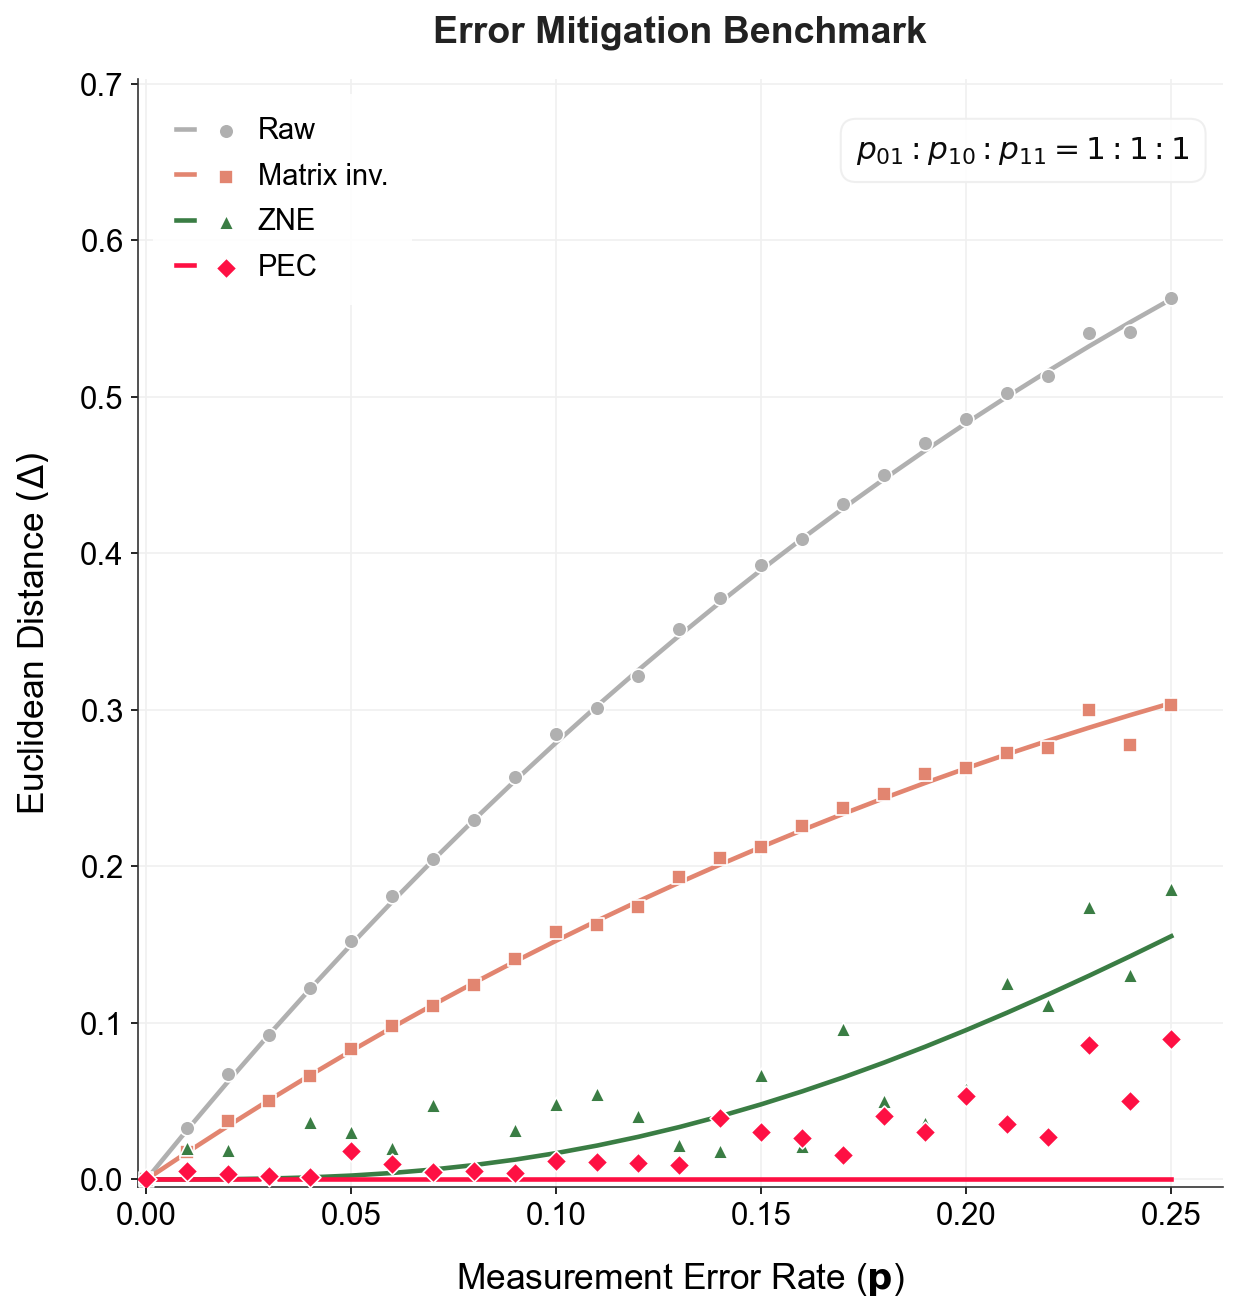

In [17]:
p_vals_111, mse_records_111 = run_integrated_qem_sweep(
    target_gate='U_pi/3',          
    u_state='+',              
    error_profile=(1, 1, 1),    
    lam_max=3.0,              
    l=5,                      
    shots=30000
)

  QEM PIPELINE SWEEP INITIALIZED
  [Configuration]
   - Random Seed   : 935855
   - Target Gate   : U_pi/3
   - Initial State : |+>
   - Error Profile : (1, 0, 0)
   - QPE Depth (l) : 5
   - ZNE Nodes (N) : 3 (Max λ=3.0)
------------------------------------------------------------
  * Ideal Reference Vector (Oc, Os): (0.7500, 0.4059)

  [Quantitative Analysis Results]
 1. MSE Extraction at Target Error Rates:
    [p = 0.050]
     - Raw MSE : 1.4932e-01
     - M3  MSE : 5.8544e-02 (Reduction: 2.6x)
     - ZNE MSE : 3.6643e-03 (Reduction: 40.8x)
     - PEC MSE : 2.7756e-16 (Reduction: 537985728440569.1x)
    [p = 0.100]
     - Raw MSE : 2.7707e-01
     - M3  MSE : 1.0375e-01 (Reduction: 2.7x)
     - ZNE MSE : 2.2915e-02 (Reduction: 12.1x)
     - PEC MSE : 1.5701e-16 (Reduction: 1764672808708129.2x)

 2. ZNE Polynomial Fitting (Observing Suppression)
    - Fitted Equation: MSE_ZNE ≈ (-5.26e+00)*p^3 + (4.65e+00)*p^2 + (-1.93e-01)*p^1 + (1.61e-03)

[*] Simulation data successfully saved to:

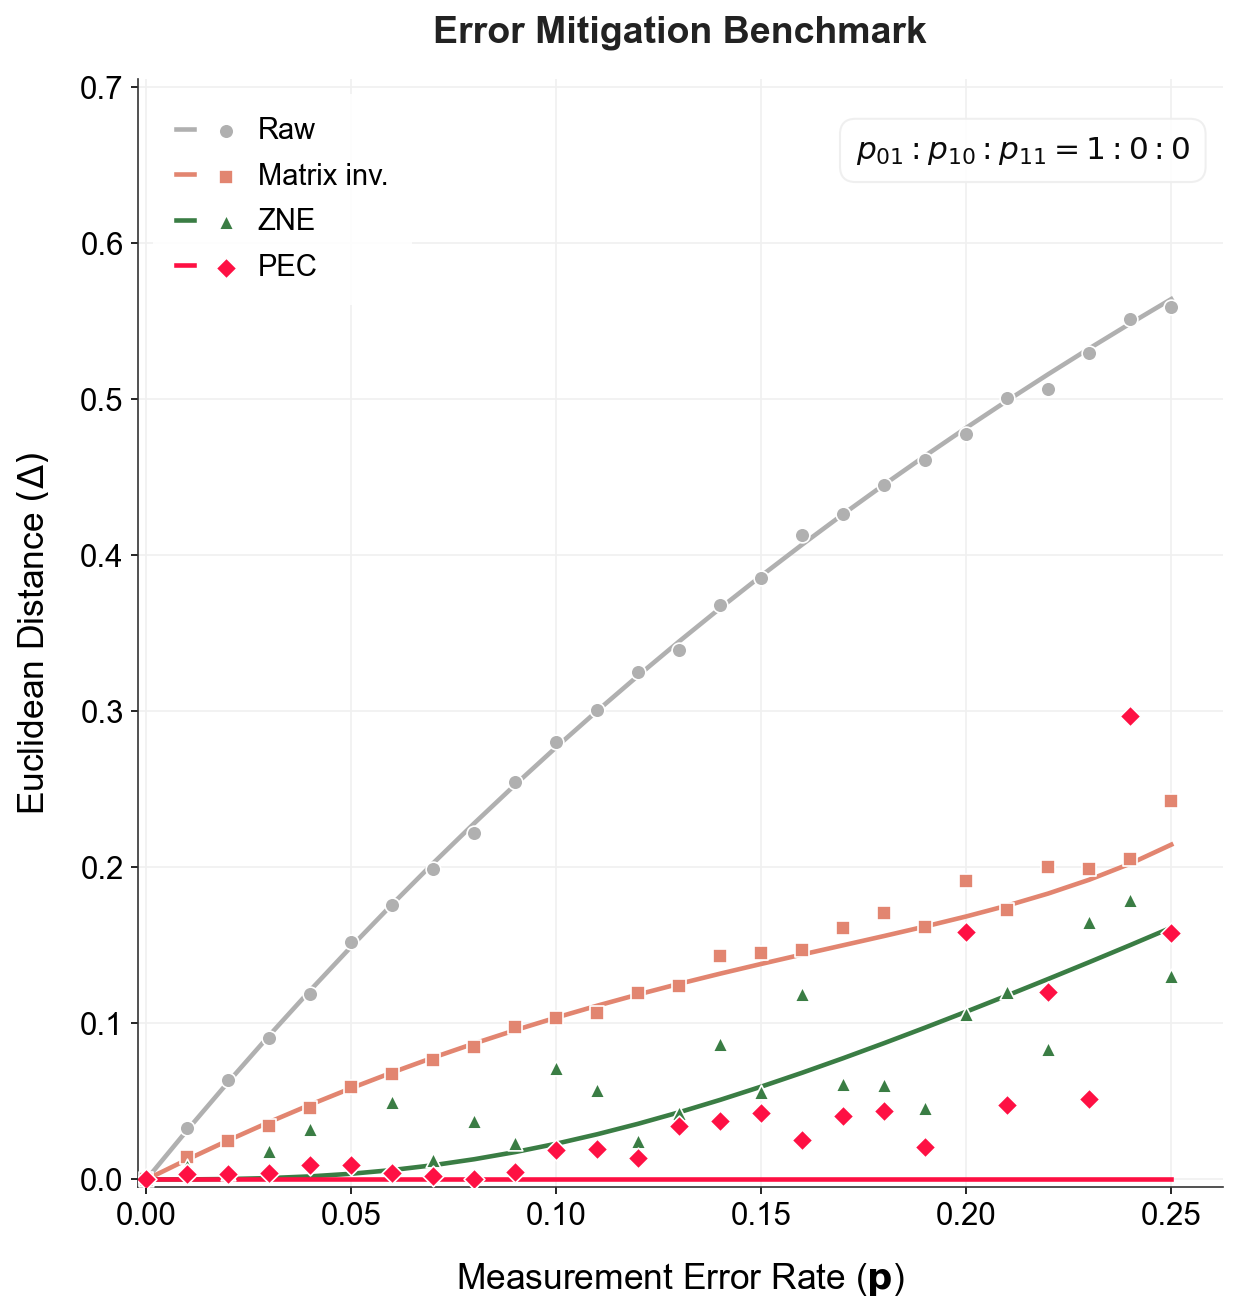

In [18]:
p_vals_100, mse_records_100 = run_integrated_qem_sweep(
    target_gate='U_pi/3',          
    u_state='+',              
    error_profile=(1, 0, 0),    
    lam_max=3.0,              
    l=5,                      
    shots=30000
)

  QEM PIPELINE SWEEP INITIALIZED
  [Configuration]
   - Random Seed   : 228800
   - Target Gate   : U_pi/3
   - Initial State : |+>
   - Error Profile : (0, 1, 0)
   - QPE Depth (l) : 5
   - ZNE Nodes (N) : 3 (Max λ=3.0)
------------------------------------------------------------
  * Ideal Reference Vector (Oc, Os): (0.7500, 0.4059)

  [Quantitative Analysis Results]
 1. MSE Extraction at Target Error Rates:
    [p = 0.050]
     - Raw MSE : 1.4657e-01
     - M3  MSE : 1.4657e-01 (Reduction: 1.0x)
     - ZNE MSE : 2.6257e-03 (Reduction: 55.8x)
     - PEC MSE : 2.4825e-16 (Reduction: 590407222597272.2x)
    [p = 0.100]
     - Raw MSE : 2.7365e-01
     - M3  MSE : 2.7365e-01 (Reduction: 1.0x)
     - ZNE MSE : 1.8201e-02 (Reduction: 15.0x)
     - PEC MSE : 0.0000e+00 (Reduction: 0.0x)

 2. ZNE Polynomial Fitting (Observing Suppression)
    - Fitted Equation: MSE_ZNE ≈ (-4.16e+00)*p^3 + (4.43e+00)*p^2 + (-2.35e-01)*p^1 + (2.42e-03)

[*] Simulation data successfully saved to: ./simulation_r

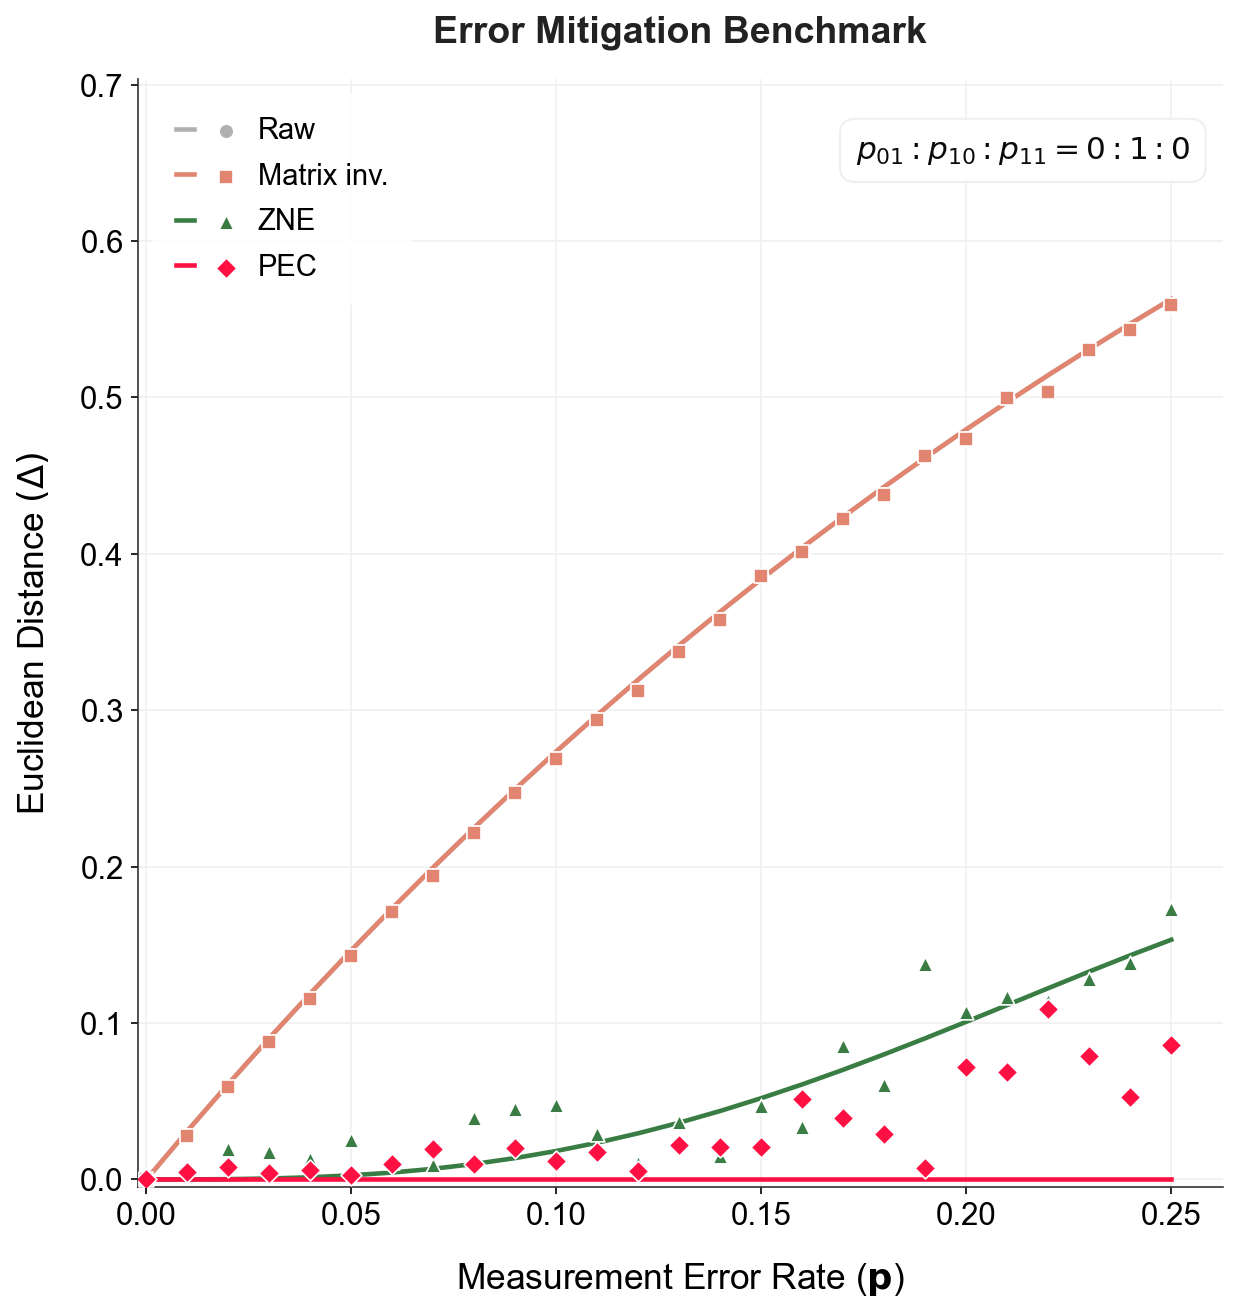

In [19]:
p_vals_010, mse_records_010 = run_integrated_qem_sweep(
    target_gate='U_pi/3',          
    u_state='+',              
    error_profile=(0, 1, 0),    
    lam_max=3.0,              
    l=5,                      
    shots=30000
)

  QEM PIPELINE SWEEP INITIALIZED
  [Configuration]
   - Random Seed   : 620981
   - Target Gate   : U_pi/3
   - Initial State : |+>
   - Error Profile : (0, 0, 1)
   - QPE Depth (l) : 5
   - ZNE Nodes (N) : 3 (Max λ=3.0)
------------------------------------------------------------
  * Ideal Reference Vector (Oc, Os): (0.7500, 0.4059)

  [Quantitative Analysis Results]
 1. MSE Extraction at Target Error Rates:
    [p = 0.050]
     - Raw MSE : 1.5834e-01
     - M3  MSE : 7.2436e-02 (Reduction: 2.2x)
     - ZNE MSE : 1.5701e-16 (Reduction: 1008460460838066.4x)
     - PEC MSE : 3.1402e-16 (Reduction: 504230230419033.2x)
    [p = 0.100]
     - Raw MSE : 3.0044e-01
     - M3  MSE : 1.3752e-01 (Reduction: 2.2x)
     - ZNE MSE : 3.3307e-16 (Reduction: 902038374472777.5x)
     - PEC MSE : 0.0000e+00 (Reduction: 0.0x)

 2. ZNE Polynomial Fitting (Observing Suppression)
    - Fitted Equation: MSE_ZNE ≈ (4.06e-14)*p^3 + (-1.49e-14)*p^2 + (2.95e-16)*p^1 + (5.20e-16)

[*] Simulation data successfull

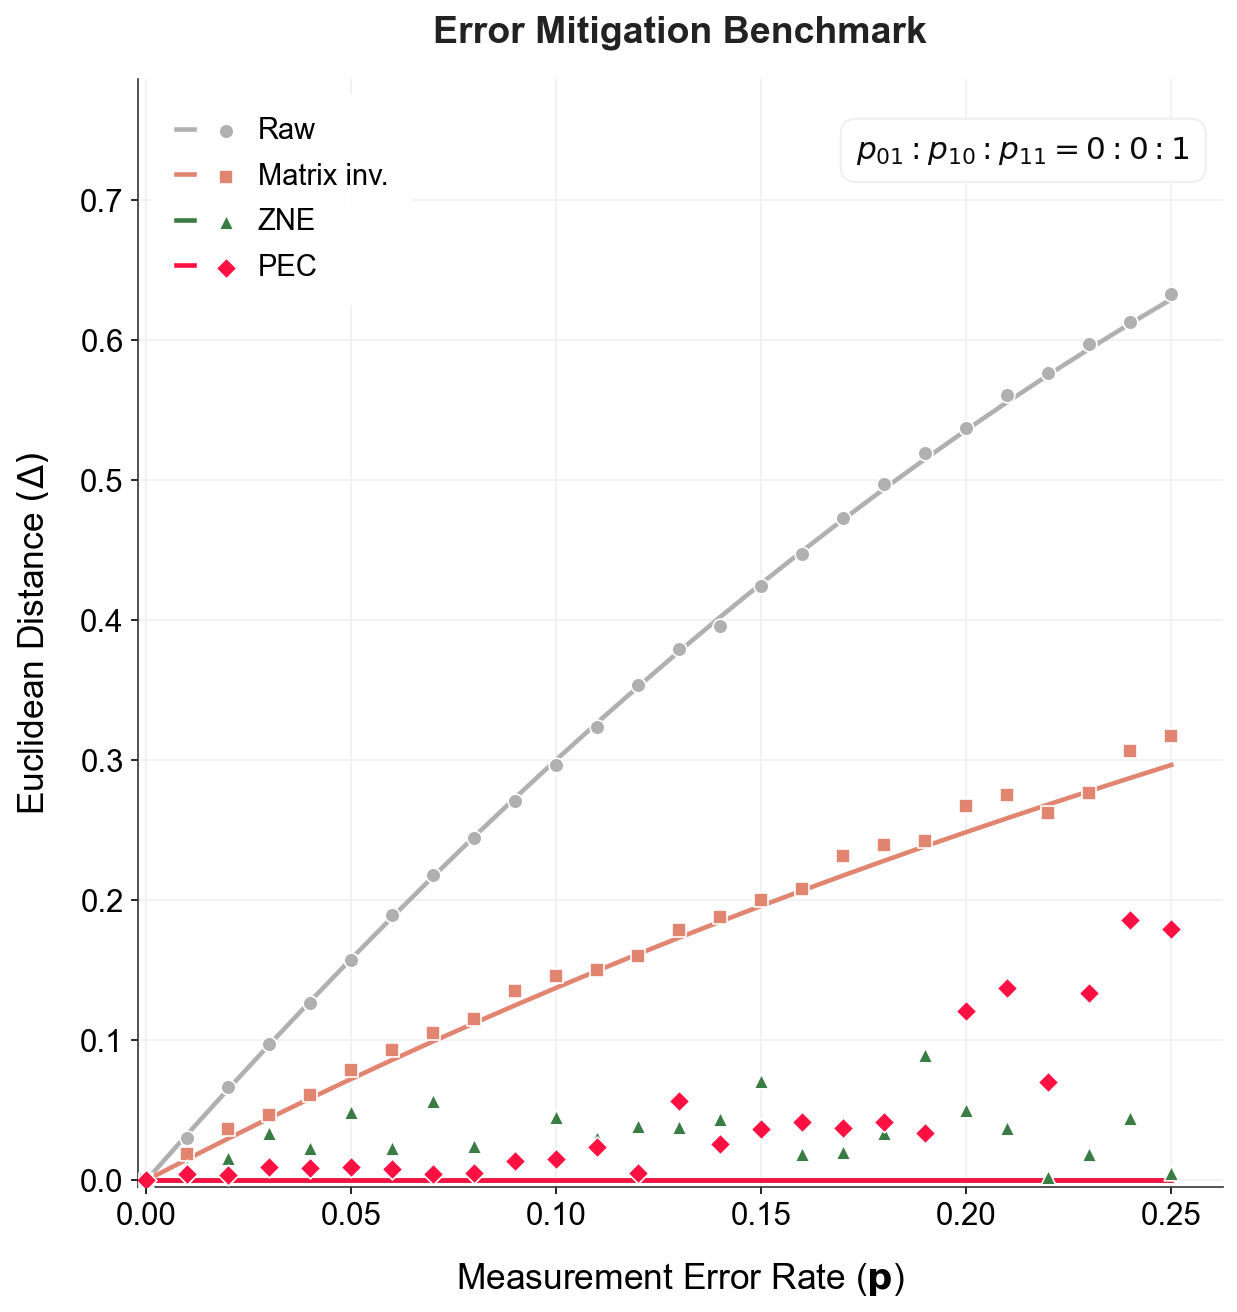

In [2]:
p_vals_001, mse_records_001 = run_integrated_qem_sweep(
    target_gate='U_pi/3',          
    u_state='+',              
    error_profile=(0, 0, 1),    
    lam_max=3.0,              
    l=5,                      
    shots=30000
)

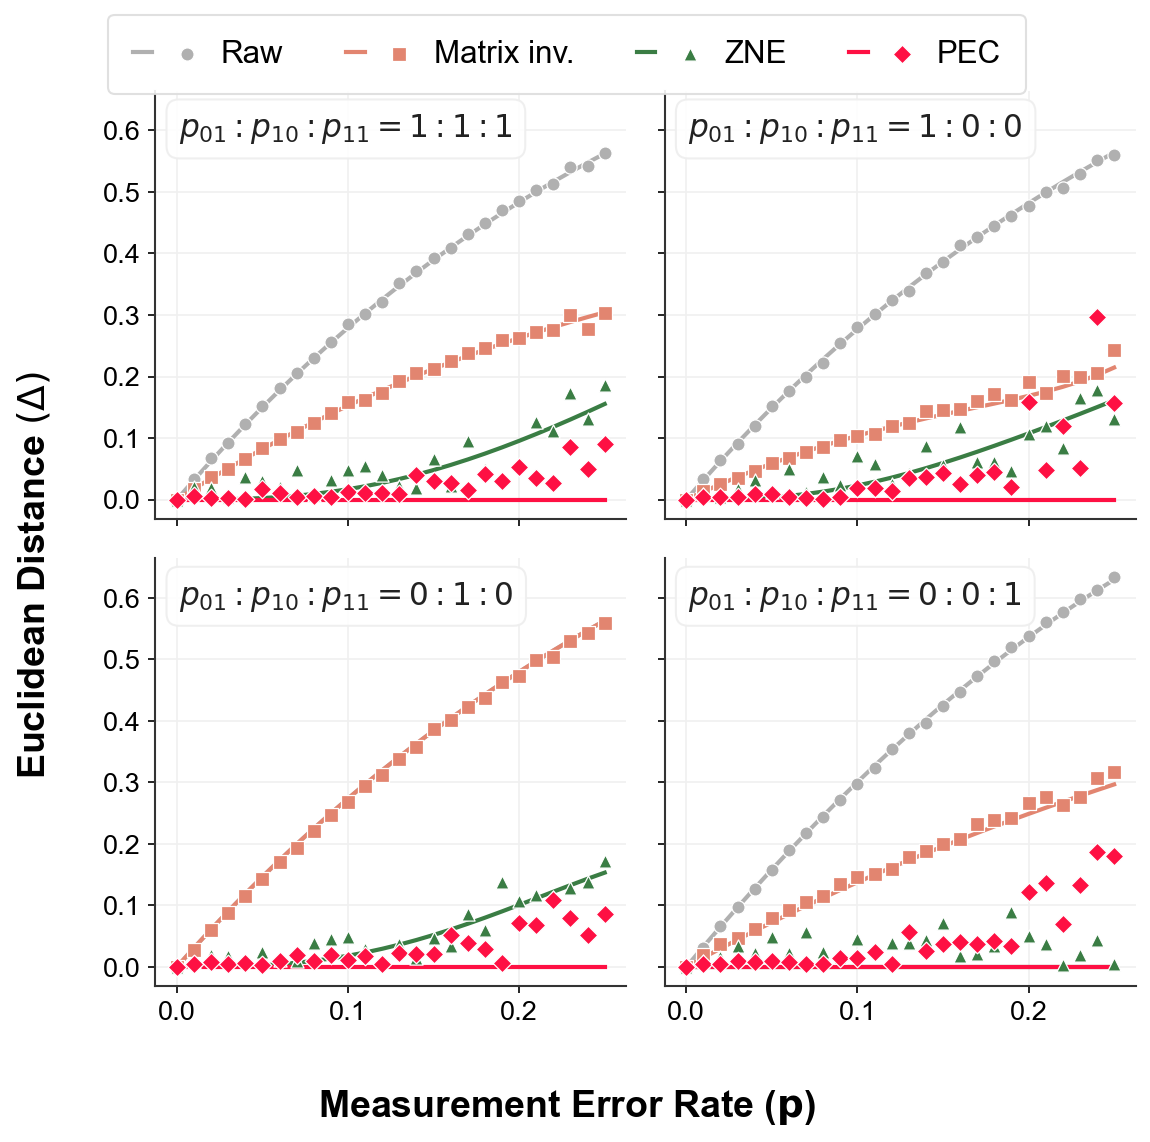

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerTuple

# -------------------------------------------------------------
# 고해상도 및 프리미엄 퍼블리케이션 스타일 커스텀 테마
# -------------------------------------------------------------
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 14,
    'axes.labelsize': 16,
    'axes.titlesize': 16,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 13,
    'axes.linewidth': 1.0,
    'axes.edgecolor': '#333333'
})

colors = {
    'raw': '#B0B0B0',  
    'm3': "#E28570",   
    'zne': '#3A7D44',  
    'pec': "#FE1043"   
}
m_size = 40

# JSON 파일 경로 리스트 (순서: 1:1:1, 1:0:0, 0:1:0, 0:0:1)
# 실제 파일 경로에 맞게 수정해주세요.
file_paths = [
    "qem_data_U_pi_3_shots30000_seed594631_20260831_154328.json", # [1,1,1]
    "qem_data_U_pi_3_shots30000_seed935855_20260831_191459.json", # [1,0,0]
    "qem_data_U_pi_3_shots30000_seed228800_20260831_224604.json", # [0,1,0]
    "qem_data_U_pi_3_shots30000_seed620981_20260901_171221.json"  # [0,0,1]
]

fig, axes = plt.subplots(2, 2, figsize=(8, 8), sharex=True, sharey=True, dpi=150)
axes = axes.flatten()

# 범례 핸들 저장을 위한 리스트
global_legend_handles = []
global_legend_labels = ['Raw', 'Matrix inv.', 'ZNE', 'PEC']

for i, (ax, fpath) in enumerate(zip(axes, file_paths)):
    with open(fpath, 'r') as f:
        data = json.load(f)
    
    p_vals = data['p_vals']
    mse = data['mse_records']
    profile = data['metadata']['error_profile']
    
    # -------------------- 플로팅 --------------------
    l_raw, = ax.plot(p_vals, mse['ana_raw'], '-', color=colors['raw'], linewidth=2.0, zorder=2)
    s_raw = ax.scatter(p_vals, mse['num_raw'], marker='o', color=colors['raw'], s=m_size, edgecolor='white', linewidths=0.6, zorder=5)

    l_m3, = ax.plot(p_vals, mse['ana_m3'], '-', color=colors['m3'], linewidth=2.0, zorder=2)
    s_m3 = ax.scatter(p_vals, mse['num_m3'], marker='s', color=colors['m3'], s=m_size, edgecolor='white', linewidths=0.6, zorder=5)

    l_zne, = ax.plot(p_vals, mse['ana_zne'], '-', color=colors['zne'], linewidth=2.0, zorder=2)
    s_zne = ax.scatter(p_vals, mse['num_zne'], marker='^', color=colors['zne'], s=m_size, edgecolor='white', linewidths=0.6, zorder=5)

    l_pec, = ax.plot(p_vals, mse['ana_pec'], '-', color=colors['pec'], linewidth=2.0, zorder=2)
    s_pec = ax.scatter(p_vals, mse['num_pec'], marker='D', color=colors['pec'], s=m_size, edgecolor='white', linewidths=0.6, zorder=5)
    
    # 범례 핸들 저장 (첫 번째 서브플롯에서만)
    if i == 0:
        global_legend_handles = [(l_raw, s_raw), (l_m3, s_m3), (l_zne, s_zne), (l_pec, s_pec)]
        
    # -------------------- 텍스트 및 서식 --------------------
    ratio_str = r"$p_{01} : p_{10} : p_{11} = " + f"{profile[0]} : {profile[1]} : {profile[2]}$"
    ax.text(0.05, 0.95, ratio_str, transform=ax.transAxes, ha='left', va='top', 
            fontsize=15, color="#222222", 
            bbox=dict(facecolor='white', edgecolor='#EEEEEE', boxstyle='round,pad=0.4', alpha=0.9), zorder=10)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, linestyle='-', color='#F0F0F0', linewidth=0.8, zorder=0)

# -------------------- 전체 축 라벨 및 범례 설정 --------------------
fig.supxlabel(r'Measurement Error Rate ($\mathbf{p}$)', fontsize=18, fontweight='bold', y=0.04)
fig.supylabel(r'Euclidean Distance $(\Delta)$', fontsize=18, fontweight='bold', x=0.04)

# 전체 플롯 상단 중앙에 범례 배치
fig.legend(
    global_legend_handles, global_legend_labels,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc='upper center', bbox_to_anchor=(0.5, 0.98),
    ncol=4, frameon=True, facecolor='#ffffff', edgecolor='#DDDDDD',
    framealpha=0.9, borderpad=0.8, labelspacing=0.6, fontsize=15
)

# 레이아웃 조정 (범례와 전체 라벨이 잘리지 않도록 여백 확보)
plt.tight_layout(rect=[0.03, 0.04, 1, 0.93])
plt.show()

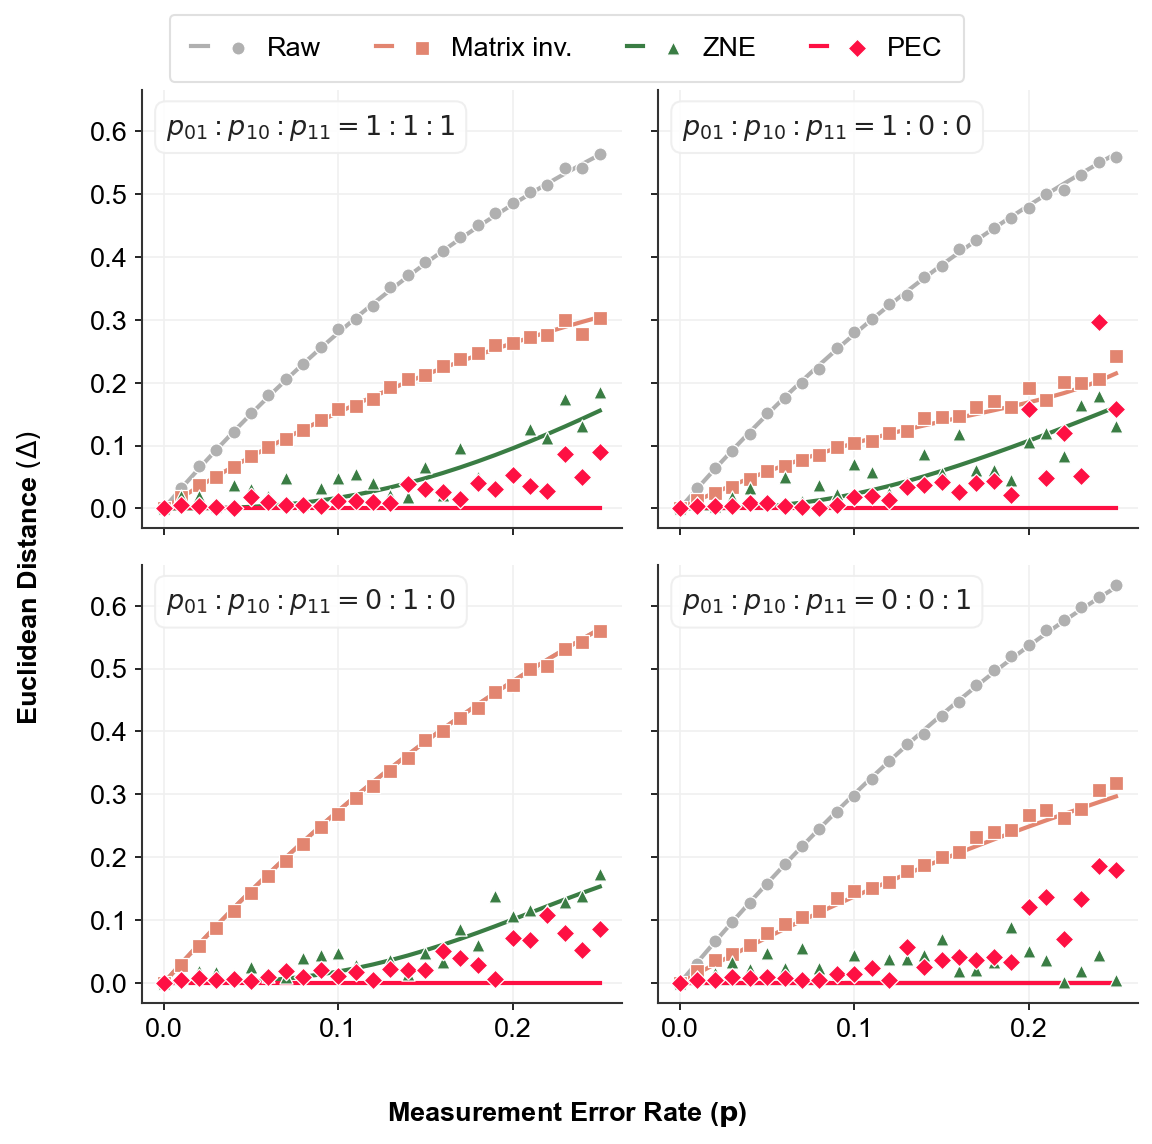

In [6]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerTuple

# -------------------------------------------------------------
# 고해상도 및 프리미엄 퍼블리케이션 스타일 커스텀 테마
# -------------------------------------------------------------
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 13,          # 전체 기본 폰트
    'axes.labelsize': 13,     # 개별 축 라벨
    'axes.titlesize': 13,     # 타이틀
    'xtick.labelsize': 13,    # x축 눈금
    'ytick.labelsize': 13,    # y축 눈금
    'legend.fontsize': 13,    # 범례 기본 폰트
    'axes.linewidth': 1.0,
    'axes.edgecolor': '#333333'
})

colors = {
    'raw': '#B0B0B0',  
    'm3': "#E28570",   
    'zne': '#3A7D44',  
    'pec': "#FE1043"   
}
m_size = 40

# JSON 파일 경로 리스트 (순서: 1:1:1, 1:0:0, 0:1:0, 0:0:1)
# 실제 파일 경로에 맞게 수정해주세요.
file_paths = [
    "qem_data_U_pi_3_shots30000_seed594631_20260831_154328.json", # [1,1,1]
    "qem_data_U_pi_3_shots30000_seed935855_20260831_191459.json", # [1,0,0]
    "qem_data_U_pi_3_shots30000_seed228800_20260831_224604.json", # [0,1,0]
    "qem_data_U_pi_3_shots30000_seed620981_20260901_171221.json"  # [0,0,1]
]

fig, axes = plt.subplots(2, 2, figsize=(8, 8), sharex=True, sharey=True, dpi=150)
axes = axes.flatten()

# 범례 핸들 저장을 위한 리스트
global_legend_handles = []
global_legend_labels = ['Raw', 'Matrix inv.', 'ZNE', 'PEC']

for i, (ax, fpath) in enumerate(zip(axes, file_paths)):
    with open(fpath, 'r') as f:
        data = json.load(f)
    
    p_vals = data['p_vals']
    mse = data['mse_records']
    profile = data['metadata']['error_profile']
    
    # -------------------- 플로팅 --------------------
    l_raw, = ax.plot(p_vals, mse['ana_raw'], '-', color=colors['raw'], linewidth=2.0, zorder=2)
    s_raw = ax.scatter(p_vals, mse['num_raw'], marker='o', color=colors['raw'], s=m_size, edgecolor='white', linewidths=0.6, zorder=5)

    l_m3, = ax.plot(p_vals, mse['ana_m3'], '-', color=colors['m3'], linewidth=2.0, zorder=2)
    s_m3 = ax.scatter(p_vals, mse['num_m3'], marker='s', color=colors['m3'], s=m_size, edgecolor='white', linewidths=0.6, zorder=5)

    l_zne, = ax.plot(p_vals, mse['ana_zne'], '-', color=colors['zne'], linewidth=2.0, zorder=2)
    s_zne = ax.scatter(p_vals, mse['num_zne'], marker='^', color=colors['zne'], s=m_size, edgecolor='white', linewidths=0.6, zorder=5)

    l_pec, = ax.plot(p_vals, mse['ana_pec'], '-', color=colors['pec'], linewidth=2.0, zorder=2)
    s_pec = ax.scatter(p_vals, mse['num_pec'], marker='D', color=colors['pec'], s=m_size, edgecolor='white', linewidths=0.6, zorder=5)
    
    # 범례 핸들 저장 (첫 번째 서브플롯에서만)
    if i == 0:
        global_legend_handles = [(l_raw, s_raw), (l_m3, s_m3), (l_zne, s_zne), (l_pec, s_pec)]
        
    # -------------------- 텍스트 및 서식 --------------------
    ratio_str = r"$p_{01} : p_{10} : p_{11} = " + f"{profile[0]} : {profile[1]} : {profile[2]}$"
    ax.text(0.05, 0.95, ratio_str, transform=ax.transAxes, ha='left', va='top', 
            fontsize=13, color="#222222", # 13으로 통일
            bbox=dict(facecolor='white', edgecolor='#EEEEEE', boxstyle='round,pad=0.4', alpha=0.9), zorder=10)
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, linestyle='-', color='#F0F0F0', linewidth=0.8, zorder=0)

# -------------------- 전체 축 라벨 및 범례 설정 --------------------
fig.supxlabel(r'Measurement Error Rate ($\mathbf{p}$)', fontsize=13, fontweight='bold', y=0.04) # 13으로 통일
fig.supylabel(r'Euclidean Distance $(\Delta)$', fontsize=13, fontweight='bold', x=0.04) # 13으로 통일

# 전체 플롯 상단 중앙에 범례 배치
fig.legend(
    global_legend_handles, global_legend_labels,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc='upper center', bbox_to_anchor=(0.5, 0.98),
    ncol=4, frameon=True, facecolor='#ffffff', edgecolor='#DDDDDD',
    framealpha=0.9, borderpad=0.8, labelspacing=0.6, fontsize=13 # 13으로 통일
)

# 레이아웃 조정 (범례와 전체 라벨이 잘리지 않도록 여백 확보)
plt.tight_layout(rect=[0.03, 0.04, 1, 0.93])
plt.show()

In [2]:
import json
import numpy as np

file_paths = [
    "qem_data_U_pi_3_shots30000_seed594631_20260831_154328.json",
    "qem_data_U_pi_3_shots30000_seed935855_20260831_191459.json",
    "qem_data_U_pi_3_shots30000_seed228800_20260831_224604.json",
    "qem_data_U_pi_3_shots30000_seed620981_20260901_171221.json"
]

target_p = 0.25
pec_diffs, zne_diffs = [], []

for fpath in file_paths:
    with open(fpath, 'r') as f:
        data = json.load(f)
        
    p_index = data['p_vals'].index(target_p)
    
    # PEC 편차
    ana_pec = data['mse_records']['ana_pec'][p_index]
    num_pec = data['mse_records']['num_pec'][p_index]
    pec_diffs.append(abs(num_pec - ana_pec))
    
    # ZNE 편차
    ana_zne = data['mse_records']['ana_zne'][p_index]
    num_zne = data['mse_records']['num_zne'][p_index]
    zne_diffs.append(abs(num_zne - ana_zne))

print(f"Average PEC Discrepancy at p={target_p}: {np.mean(pec_diffs):.3f}")
print(f"Average ZNE Discrepancy at p={target_p}: {np.mean(zne_diffs):.3f}")

Average PEC Discrepancy at p=0.25: 0.128
Average ZNE Discrepancy at p=0.25: 0.021


 [Single Point QEM Inspection] p = 0.25

[IDEAL (Noiseless) Distribution & Phase Vector]
 - Phase Vector (Oc, Os) : (0.75000, 0.40595)
 - Distance to Ideal (Δ²) : 0.00000e+00
 - Top 6 Bitstrings:
    |00000> (φ=0.0000): 0.50146
    |00101> (φ=0.1562): 0.34208
    |00110> (φ=0.1875): 0.08561
    |00100> (φ=0.1250): 0.02149
    |00111> (φ=0.2188): 0.01380
    |00011> (φ=0.0938): 0.00710

[RAW (Unmitigated) Distribution & Phase Vector]
 - Phase Vector (Oc, Os) : (0.19922, 0.10149)
 - Distance to Ideal (Δ²) : 6.29331e-01
 - Top 6 Bitstrings:
    |00000> (φ=0.0000): 0.12909
    |00101> (φ=0.1562): 0.08921
    |10000> (φ=0.5000): 0.04816
    |00100> (φ=0.1250): 0.04453
    |01000> (φ=0.2500): 0.04021
    |00110> (φ=0.1875): 0.03828

[Matrix Inversion Mitigated Distribution & Phase Vector]
 - Phase Vector (Oc, Os) : (0.71424, 0.11146)
 - Distance to Ideal (Δ²) : 2.96652e-01
 - Top 6 Bitstrings:
    |00000> (φ=0.0000): 0.69304
    |00101> (φ=0.1562): 0.49173
    |00001> (φ=0.0312): -0.26579
  

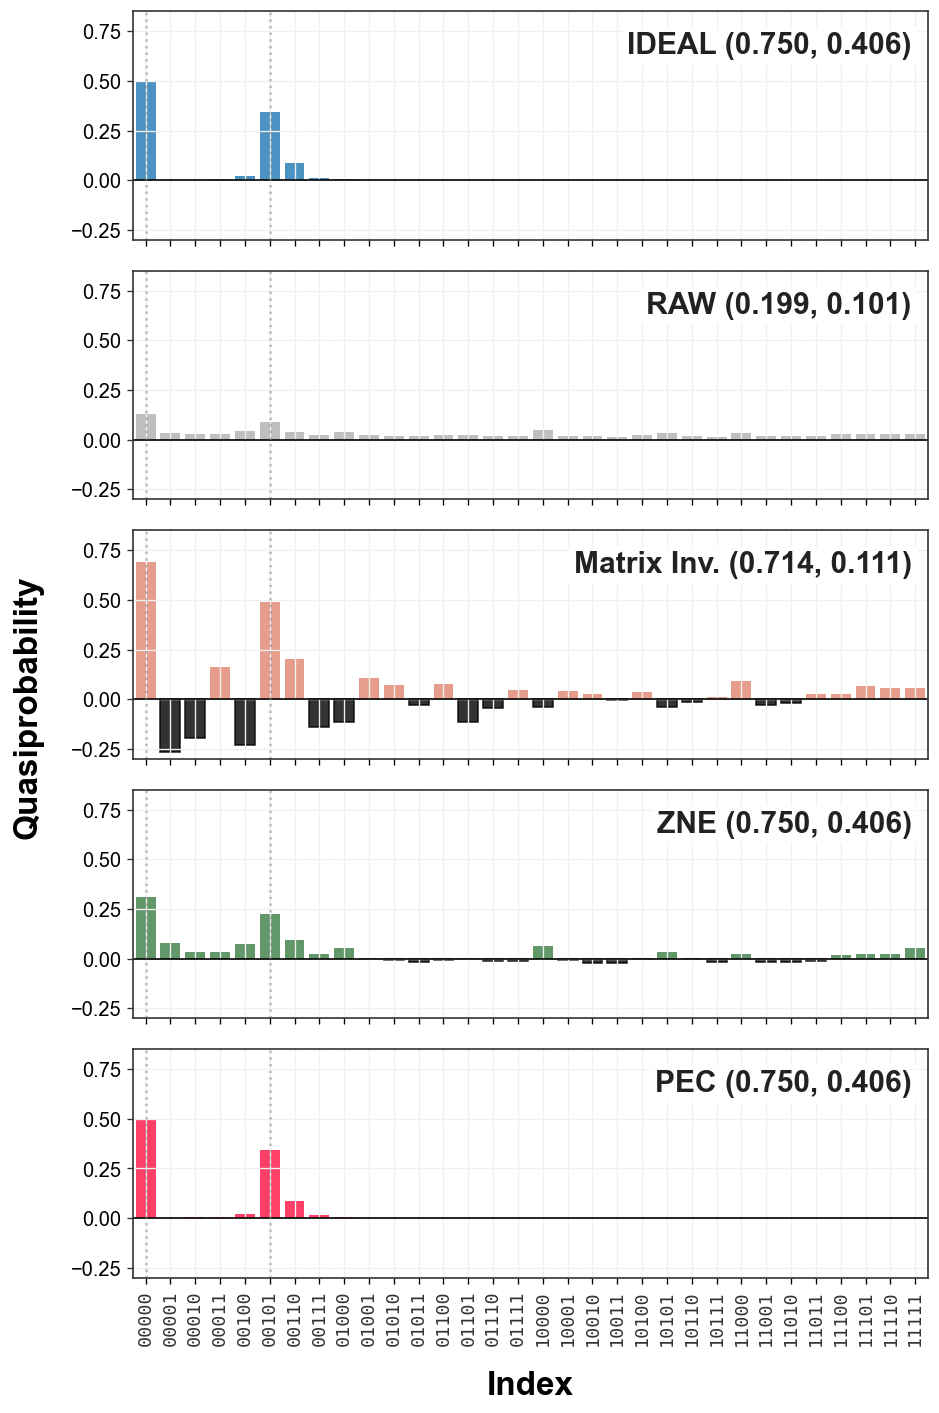

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def inspect_single_error_rate(target_gate='U_pi/3', u_state='+', p=0.05, error_profile=(0,0,1), N_nodes=3, lam_max=3.0, l=7):
    print("="*70)
    print(f" [Single Point QEM Inspection] p = {p}")
    print("="*70)
    
    # 1. 파라미터 세팅
    lam_points = get_chebyshev_lobatto_nodes(1.0, lam_max, N_nodes)
    rich_weights = get_richardson_weights(lam_points)
    bitstrings = [f"{i:0{l}b}" for i in range(2**l)]
    
    p_ratio = np.array(error_profile, dtype=float)
    p_ratio /= np.sum(p_ratio)
    p01, p10, p11 = p * p_ratio[0], p * p_ratio[1], p * p_ratio[2]
    
    # 2. 분포 계산
    dist_ideal = qpe_analytical(target_gate, u_state, 0.0, 0.0, 0.0, "raw", 1.0, l)
    dist_raw = qpe_analytical(target_gate, u_state, p10, p01, p11, "raw", 1.0, l)
    dist_m3 = apply_m3_mitigation(dist_raw, p01, p11, l)
    
    dist_exact_zne = {lam: qpe_analytical(target_gate, u_state, p10, p01, p11, "raw", lam, l) for lam in lam_points}
    zne_probs = np.zeros(2**l)
    for i, lam in enumerate(lam_points):
        zne_probs += rich_weights[i] * np.array([dist_exact_zne[lam][b] for b in bitstrings])
    dist_zne = {b: val for b, val in zip(bitstrings, zne_probs)}
    
    dist_pec = qpe_analytical(target_gate, u_state, p10, p01, p11, "pec", l=l)

    # 3. Phase Vector 계산
    vec_ideal = calc_phase_vector(dist_ideal, l)
    vec_raw   = calc_phase_vector(dist_raw, l)
    vec_m3    = calc_phase_vector(dist_m3, l)
    vec_zne   = calc_phase_vector(dist_zne, l)
    vec_pec   = calc_phase_vector(dist_pec, l)
    
    # 4. 결과 출력 포맷팅
    def print_top_k(dist, vec, name, top_k=5):
        sorted_items = sorted(dist.items(), key=lambda x: abs(x[1]), reverse=True)
        print(f"\n[{name} Distribution & Phase Vector]")
        print(f" - Phase Vector (Oc, Os) : ({vec[0]:.5f}, {vec[1]:.5f})")
        print(f" - Distance to Ideal (Δ²) : {calc_phase_mse(vec, vec_ideal):.5e}")
        print(f" - Top {top_k} Bitstrings:")
        for b, prob in sorted_items[:top_k]:
            phase_val = int(b, 2) / (2**l)
            print(f"    |{b}> (φ={phase_val:.4f}): {prob:.5f}")
            
    print_top_k(dist_ideal, vec_ideal, "IDEAL (Noiseless)", top_k=6)
    print_top_k(dist_raw, vec_raw, "RAW (Unmitigated)", top_k=6)
    print_top_k(dist_m3, vec_m3, "Matrix Inversion Mitigated", top_k=6)
    print_top_k(dist_zne, vec_zne, "ZNE Mitigated", top_k=6)
    print_top_k(dist_pec, vec_pec, "PEC Mitigated", top_k=6)
    print("\n" + "="*70)

# ==========================================
    # 5. 히스토그램 시각화 로직 추가
# ==========================================
    # 고해상도 및 프리미엄 퍼블리케이션 스타일 커스텀 테마 (Sans-serif 계열)
    plt.rcParams.update({
        'font.family': 'sans-serif',
        'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
        'font.size': 14,
        'axes.labelsize': 16,
        'axes.titlesize': 16,
        'xtick.labelsize': 12,
        'ytick.labelsize': 12,
        'axes.linewidth': 1.0,
        'axes.edgecolor': '#333333'
    })

    fig, axes = plt.subplots(5, 1, figsize=(8, 12), sharex=True, dpi=120) 
    dists = [dist_ideal, dist_raw, dist_m3, dist_zne, dist_pec]

    # 통합 Y축 라벨 (x 좌표를 조정하여 그래프와 더 가깝게 배치)
    fig.supylabel("Quasiprobability", fontsize=20, fontweight='bold', x=0.02)
    
    # 타이틀 텍스트 설정 (좌표만 심플하게 표기)
    inner_labels = [
        f'IDEAL ({vec_ideal[0]:.3f}, {vec_ideal[1]:.3f})', 
        f'RAW ({vec_raw[0]:.3f}, {vec_raw[1]:.3f})', 
        f'Matrix Inv. ({vec_m3[0]:.3f}, {vec_m3[1]:.3f})', 
        f'ZNE ({vec_zne[0]:.3f}, {vec_zne[1]:.3f})', 
        f'PEC ({vec_pec[0]:.3f}, {vec_pec[1]:.3f})'
    ]
    colors = ['#1f77b4', '#B0B0B0', '#E28570', '#3A7D44', '#FE1043']
    
    x_vals = np.arange(2**l)
    x_labels = [f"{x:0{l}b}" for x in x_vals]
    
    for i, (ax, dist, label, color) in enumerate(zip(axes, dists, inner_labels, colors)):
        y_vals = [dist.get(f"{x:0{l}b}", 0) for x in x_vals]
        
        bars = ax.bar(x_vals, y_vals, color=color, alpha=0.8, width=0.8) 
        
        for bar, y in zip(bars, y_vals):
            if y < 0:
                bar.set_color("#000000")
                
        # 그래프 안쪽 우측 상단에 라벨 텍스트 배치
        ax.text(
            0.98, 0.85, label, 
            transform=ax.transAxes, ha='right', va='center', 
            fontsize=18, fontweight='bold', color='#222222',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='none', pad=3)
        )
        
        ax.axhline(0, color='black', linewidth=1.0)
        ax.grid(True, linestyle='-', color='#F0F0F0', linewidth=0.8, zorder=0)
        
        # y축 눈금 설정
        ax.tick_params(axis='y', labelsize=12, color='#333333')
        
        ax.set_ylim(-0.3, 0.85)
        
        # X축 눈금 설정 (상태 인덱스는 고정폭 폰트 유지)
        ax.set_xticks(x_vals)
        ax.set_xticklabels(x_labels, rotation=90, fontsize=11, fontfamily='monospace', color='#333333')
        
        # 좌우 폭 최소화
        ax.set_xlim(-0.5, 2**l - 0.5)
        
        # 타겟 피크 위치 표시 
        ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
        ax.axvline(int((1/6) * (2**l)), color='gray', linestyle=':', alpha=0.5)

    # 하단 state index 추가
    axes[-1].set_xlabel("Index", fontsize=20, fontweight='bold', labelpad=15)
    
    # 통합 라벨이 잘리지 않도록 좌측 마진 세부 조정
    plt.tight_layout(rect=[0.02, 0, 1, 1]) 
    plt.show()
    
    # 폰트 설정 복구
    plt.rcdefaults()


# 실행 예시
distributions = inspect_single_error_rate(
    target_gate='U_pi/3', 
    u_state='+', 
    p=0.25, 
    l=5
)